# Generative Model Evaluation
Comparing GAN vs VAE vs CTGAN using statistical fidelity and downstream ML task

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

real = pd.read_csv('../data/adult_clean.csv')
gan = pd.read_csv('../data/synthetic_gan.csv')
vae = pd.read_csv('../data/synthetic_vae.csv')
ctgan = pd.read_csv('../data/synthetic_ctgan.csv')

print('Real:', real.shape)
print('GAN:', gan.shape)
print('VAE:', vae.shape)
print('CTGAN:', ctgan.shape)

Real: (32561, 15)
GAN: (32561, 15)
VAE: (32561, 15)
CTGAN: (32561, 15)


In [2]:
# Metric 1 — KS statistic (distribution similarity)
num_cols = real.select_dtypes(include='number').columns.tolist()

ks_results = {}
for model_name, synth in [('GAN', gan), ('VAE', vae), ('CTGAN', ctgan)]:
    ks_scores = []
    for col in num_cols:
        if col in synth.columns:
            stat, _ = stats.ks_2samp(real[col].dropna(), synth[col].dropna())
            ks_scores.append(stat)
    ks_results[model_name] = np.mean(ks_scores)
    print(f'{model_name} avg KS statistic: {np.mean(ks_scores):.4f}')
print('Lower KS = better')

GAN avg KS statistic: 0.4953
VAE avg KS statistic: 0.7215
CTGAN avg KS statistic: 0.1254
Lower KS = better


In [3]:
# Metric 2 — Correlation matrix similarity
def corr_similarity(real_df, synth_df):
    cols = real_df.select_dtypes(include='number').columns
    real_corr = real_df[cols].corr().values
    synth_corr = synth_df[cols].corr().values
    return 1 - np.mean(np.abs(real_corr - synth_corr))

corr_results = {}
for model_name, synth in [('GAN', gan), ('VAE', vae), ('CTGAN', ctgan)]:
    score = corr_similarity(real, synth)
    corr_results[model_name] = score
    print(f'{model_name} correlation similarity: {score:.4f}')
print('Higher = better')

GAN correlation similarity: 0.9433
VAE correlation similarity: 0.2845
CTGAN correlation similarity: 0.9667
Higher = better


In [4]:
# Metric 3 — TSTR (Train on Synthetic, Test on Real)
def encode_df(df):
    df_enc = df.copy()
    for col in df_enc.select_dtypes(include='object').columns:
        df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))
    df_enc = df_enc.fillna(df_enc.median(numeric_only=True))
    # Fix target — round to 0/1
    df_enc['income'] = df_enc['income'].round().astype(int).clip(0, 1)
    return df_enc

real_enc = encode_df(real)
X_real = real_enc.drop('income', axis=1)
y_real = real_enc['income']
X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42
)

tstr_results = {}
for model_name, synth in [('GAN', gan), ('VAE', vae), ('CTGAN', ctgan)]:
    synth_enc = encode_df(synth)
    synth_enc = synth_enc.reindex(columns=real_enc.columns, fill_value=0)
    X_synth = synth_enc.drop('income', axis=1)
    y_synth = synth_enc['income']

    # Skip if only one class present
    if len(y_synth.unique()) < 2:
        print(f'{model_name}: only one class in synthetic target — skipping TSTR')
        tstr_results[model_name] = 0.5
        continue

    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf.fit(X_synth, y_synth)
    y_prob = clf.predict_proba(X_test_real)[:,1]
    auc = roc_auc_score(y_test_real, y_prob)
    tstr_results[model_name] = auc
    print(f'{model_name} TSTR AUC: {auc:.4f}')

clf_real = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf_real.fit(X_train_real, y_train_real)
baseline_auc = roc_auc_score(y_test_real, clf_real.predict_proba(X_test_real)[:,1])
print(f'\nBaseline (train on real): {baseline_auc:.4f}')

GAN TSTR AUC: 0.8214
VAE: only one class in synthetic target — skipping TSTR


CTGAN TSTR AUC: 0.8730



Baseline (train on real): 0.9101


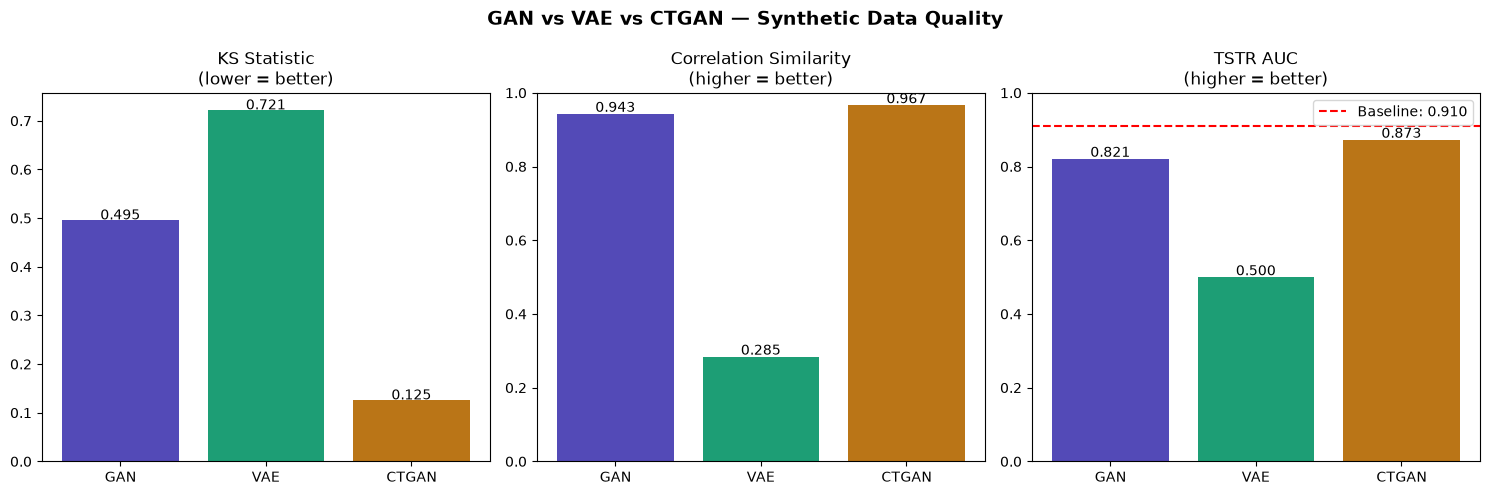

In [5]:
# Visualize all metrics
models = ['GAN', 'VAE', 'CTGAN']
colors = ['#534AB7', '#1D9E75', '#BA7517']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

ks_vals = [ks_results[m] for m in models]
bars = axes[0].bar(models, ks_vals, color=colors)
axes[0].set_title('KS Statistic\n(lower = better)')
for bar, val in zip(bars, ks_vals):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f'{val:.3f}', ha='center', fontsize=10)

corr_vals = [corr_results[m] for m in models]
bars = axes[1].bar(models, corr_vals, color=colors)
axes[1].set_title('Correlation Similarity\n(higher = better)')
axes[1].set_ylim(0, 1)
for bar, val in zip(bars, corr_vals):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f'{val:.3f}', ha='center', fontsize=10)

tstr_vals = [tstr_results[m] for m in models]
bars = axes[2].bar(models, tstr_vals, color=colors)
axes[2].axhline(y=baseline_auc, color='red', linestyle='--', label=f'Baseline: {baseline_auc:.3f}')
axes[2].set_title('TSTR AUC\n(higher = better)')
axes[2].set_ylim(0, 1)
axes[2].legend()
for bar, val in zip(bars, tstr_vals):
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f'{val:.3f}', ha='center', fontsize=10)

plt.suptitle('GAN vs VAE vs CTGAN — Synthetic Data Quality', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/evaluation_results.png', dpi=150, bbox_inches='tight')
plt.show()

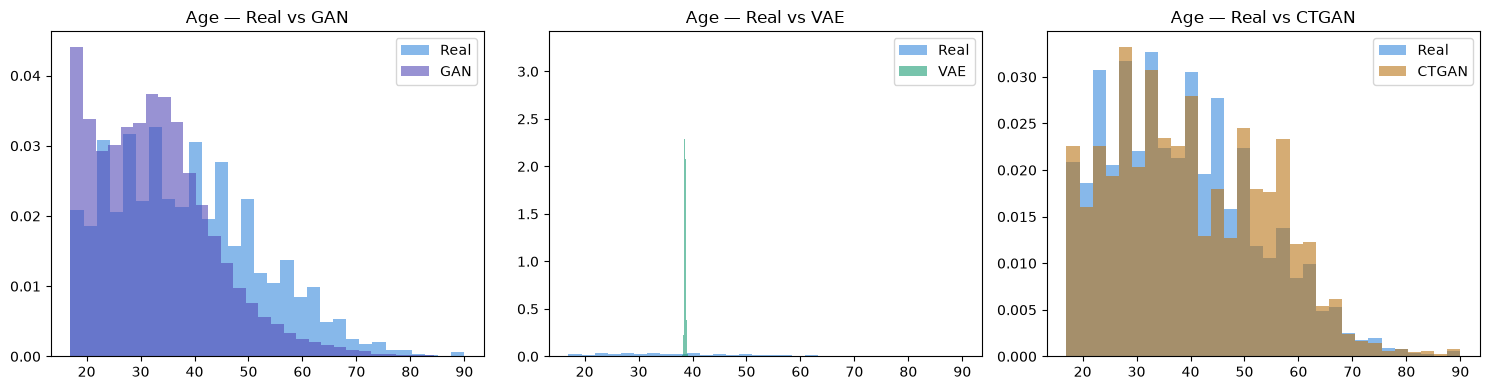

In [6]:
# Distribution comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
datasets = [('GAN', gan), ('VAE', vae), ('CTGAN', ctgan)]
col_colors = ['#534AB7', '#1D9E75', '#BA7517']

for i, (name, synth) in enumerate(datasets):
    axes[i].hist(real['age'], bins=30, alpha=0.6, color='#378ADD', label='Real', density=True)
    axes[i].hist(synth['age'], bins=30, alpha=0.6, color=col_colors[i], label=name, density=True)
    axes[i].set_title(f'Age — Real vs {name}')
    axes[i].legend()

plt.tight_layout()
plt.savefig('../data/distribution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Summary table
summary = pd.DataFrame({
    'Model': models,
    'KS Statistic': [round(ks_results[m], 4) for m in models],
    'Corr Similarity': [round(corr_results[m], 4) for m in models],
    'TSTR AUC': [round(tstr_results[m], 4) for m in models]
})
summary['TSTR gap'] = round(baseline_auc, 4) - summary['TSTR AUC']
print(f'Baseline AUC: {baseline_auc:.4f}')
print()
print(summary.to_string(index=False))
summary.to_csv('../data/evaluation_summary.csv', index=False)

Baseline AUC: 0.9101

Model  KS Statistic  Corr Similarity  TSTR AUC  TSTR gap
  GAN        0.4953           0.9433    0.8214    0.0887
  VAE        0.7215           0.2845    0.5000    0.4101
CTGAN        0.1254           0.9667    0.8730    0.0371
